# Oracle Construction — Boolean Oracle — Qiskit Notebook

**Primitive:** general Boolean-formula oracle `U_f|x>|0>_anc|0>_out = |x>|0>_anc|f(x)>_out`
for `f(x0,x1,x2) = (x0 AND x1) XOR x2`, compiled from ordinary reversible gates using the
standard "compute - copy - uncompute" pattern: `AND` via a Toffoli into a scratch ancilla,
`XOR` via `CNOT`s into the output qubit, then the ancilla is uncomputed back to `|0>` so it
can be reused/discarded. This is distinct from the earlier bit-flip oracle (a single
equality-match condition built from one big multi-controlled-X) — here the function is an
actual multi-term Boolean expression, compiled term by term.

## SETUP (must match the CUDA-Q notebook exactly)
| Parameter | Value |
|---|---|
| N_QUBITS (input register) | 3  (x0, x1, x2 — indices q0..q2, q0 = LSB) |
| ANCILLA_QUBIT | q3  (scratch qubit holding `x0 AND x1`, computed then uncomputed) |
| OUTPUT_QUBIT | q4  (accumulates `f(x0,x1,x2)`, starts at \|0>) |
| TOTAL_QUBITS | 5 |
| Boolean function | `f(x0,x1,x2) = (x0 AND x1) XOR x2` |
| SHOTS | 10000 |
| SEED | 42 |
| QUBIT ORDERING CONTRACT | qubit 0 = **rightmost** bit in every printed bitstring (Qiskit's native convention — no reversal needed in this notebook) |
| GLOBAL PHASE CONVENTION | normalize so the first amplitude with `abs(amp) > 1e-9`, taken in ascending bitstring order, is rotated to be real and positive |
| Basis ordering for matrices | `{|00000>, |00001>, ..., |11111>}` ascending binary order (32-dim, 5 qubits) |

## Theory recap

Truth table of `f(x0,x1,x2) = (x0 AND x1) XOR x2`:

| x0 | x1 | x2 | f |
|---|---|---|---|
| 0 | 0 | 0 | 0 |
| 1 | 0 | 0 | 0 |
| 0 | 1 | 0 | 0 |
| 1 | 1 | 0 | 1 |
| 0 | 0 | 1 | 1 |
| 1 | 0 | 1 | 1 |
| 0 | 1 | 1 | 1 |
| 1 | 1 | 1 | 0 |

Compiled circuit (standard AND-then-XOR pattern):

```
Toffoli(controls = q0, q1;  target = ANCILLA)   # ancilla = x0 AND x1
CNOT(control = ANCILLA;     target = OUTPUT)     # output ^= (x0 AND x1)
CNOT(control = q2;          target = OUTPUT)     # output ^= x2  -> output = f(x0,x1,x2)
Toffoli(controls = q0, q1;  target = ANCILLA)   # uncompute: ancilla back to |0>
```

The final `Toffoli` is a valid uncompute step because nothing else touches `ANCILLA` between
the two `Toffoli` calls — applying the same self-inverse gate again restores it to `|0>`
for every branch of the superposition, regardless of `x2` or the output qubit's state.

**Test harness:** `H` on the 3 input qubits only (ancilla and output start at `|0>`), so
every input pattern is explored simultaneously. Only the 4 gate lines above are the oracle
itself; the initial `H` layer is test scaffolding.

**Hand-verified structure:** after the oracle, exactly **8 of the 32** possible 5-qubit
basis states have nonzero amplitude — one per input `x`, with `ANCILLA=0` always and
`OUTPUT=f(x)` — each at probability `1/8`; all other 24 states have probability exactly `0`.

## Ordering-convention warning

Qiskit already indexes statevector amplitudes, `Operator` matrices, and measurement `counts`
keys with **qubit 0 as the least-significant (rightmost) bit** — no reversal is required in
this notebook. The CUDA-Q companion notebook indexes qubit 0 as the **most-significant
(leftmost) bit** internally and must explicitly reverse every bitstring.

**Run all cells top to bottom.**


In [1]:
# Install cell
!pip install -q qiskit qiskit-aer pylatexenc


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 37.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.5/137.5 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 1.4 MB/s eta 0:00:00


In [2]:
# Imports + constants
import numpy as np
from math import pi

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, Operator
import matplotlib.pyplot as plt

N_QUBITS = 3          # input register size (x0, x1, x2)
ANCILLA_QUBIT = 3      # scratch qubit for x0 AND x1
OUTPUT_QUBIT = 4        # accumulates f(x0,x1,x2)
TOTAL_QUBITS = 5
SHOTS = 10000
SEED = 42
TOPIC_SLUG = "bool_oracle"

def f_boolean(x0, x1, x2):
    return (x0 & x1) ^ x2

print("N_QUBITS      =", N_QUBITS)
print("ANCILLA_QUBIT =", ANCILLA_QUBIT)
print("OUTPUT_QUBIT  =", OUTPUT_QUBIT)
print("TOTAL_QUBITS  =", TOTAL_QUBITS)
print("SHOTS         =", SHOTS)
print("SEED          =", SEED)
print("\nTruth table f(x0,x1,x2) = (x0 AND x1) XOR x2:")
for x2 in range(2):
    for x1 in range(2):
        for x0 in range(2):
            print(f"  x0={x0} x1={x1} x2={x2} -> f={f_boolean(x0,x1,x2)}")


N_QUBITS      = 3
ANCILLA_QUBIT = 3
OUTPUT_QUBIT  = 4
TOTAL_QUBITS  = 5
SHOTS         = 10000
SEED          = 42

Truth table f(x0,x1,x2) = (x0 AND x1) XOR x2:
  x0=0 x1=0 x2=0 -> f=0
  x0=1 x1=0 x2=0 -> f=0
  x0=0 x1=1 x2=0 -> f=0
  x0=1 x1=1 x2=0 -> f=1
  x0=0 x1=0 x2=1 -> f=1
  x0=1 x1=0 x2=1 -> f=1
  x0=0 x1=1 x2=1 -> f=1
  x0=1 x1=1 x2=1 -> f=0


In [3]:
# Build the circuit gate-by-gate
qc = QuantumCircuit(TOTAL_QUBITS, name="BooleanOracleDemo")

for q in range(N_QUBITS):
    qc.h(q)  # test harness: uniform superposition over all 2^N_QUBITS input patterns

qc.barrier(label="oracle start")

qc.ccx(0, 1, ANCILLA_QUBIT)          # ancilla = x0 AND x1  (Toffoli implements the AND term)
qc.cx(ANCILLA_QUBIT, OUTPUT_QUBIT)    # output ^= (x0 AND x1)
qc.cx(2, OUTPUT_QUBIT)                # output ^= x2  -> output = f(x0,x1,x2)
qc.ccx(0, 1, ANCILLA_QUBIT)          # uncompute: ancilla restored to |0>

qc.barrier(label="oracle end")

print(qc)


     ┌───┐ oracle start                      oracle end 
q_0: ┤ H ├──────░─────────■──────────────■───────░──────
     ├───┤      ░         │              │       ░      
q_1: ┤ H ├──────░─────────■──────────────■───────░──────
     ├───┤      ░         │              │       ░      
q_2: ┤ H ├──────░─────────┼─────────■────┼───────░──────
     └───┘      ░       ┌─┴─┐       │  ┌─┴─┐     ░      
q_3: ───────────░───────┤ X ├──■────┼──┤ X ├─────░──────
                ░       └───┘┌─┴─┐┌─┴─┐└───┘     ░      
q_4: ───────────░────────────┤ X ├┤ X ├──────────░──────
                ░            └───┘└───┘          ░      


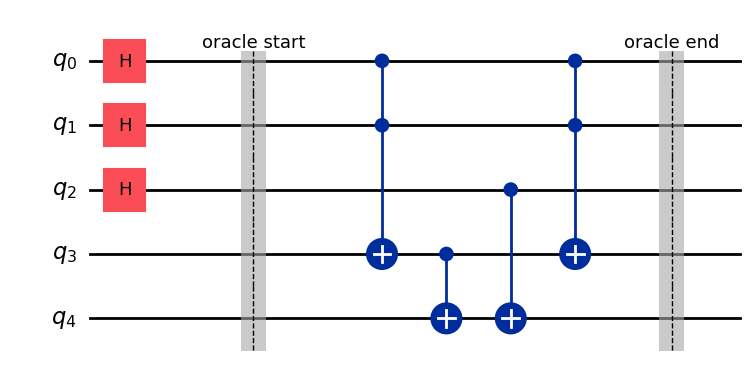

In [4]:
# Draw the circuit with matplotlib and save it
fig = qc.draw(output="mpl", style={"name": "iqp"})
fig.savefig(f"{TOPIC_SLUG}_qiskit_circuit.png", dpi=150, bbox_inches="tight")
fig


In [5]:
def h_matrix_full(n, q):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        bit = (idx >> q) & 1
        idx0 = idx & ~(1 << q); idx1 = idx | (1 << q)
        if bit == 0:
            M[idx0, idx] += 1/np.sqrt(2); M[idx1, idx] += 1/np.sqrt(2)
        else:
            M[idx1, idx] += -1/np.sqrt(2); M[idx0, idx] += 1/np.sqrt(2)
    return M

def mcx_matrix_full(n, controls, target):
    M = np.zeros((2**n, 2**n), dtype=complex)
    for idx in range(2**n):
        if all((idx >> c) & 1 for c in controls):
            M[idx ^ (1 << target), idx] = 1
        else:
            M[idx, idx] = 1
    return M

print("Toffoli (CCX) is a permutation matrix: flips the target bit iff both controls are 1.")
print("CNOT (CX) is the same construction with a single control -- both built from mcx_matrix_full below.\n")

# ============================================================
# MATRICES USED IN THE CIRCUIT
# ============================================================

H_single = (1/np.sqrt(2)) * np.array([
    [1, 1],
    [1, -1]
], dtype=complex)

print("Single-qubit H matrix:")
print(np.round(H_single, 4))

H_q0 = h_matrix_full(TOTAL_QUBITS, 0)
H_q1 = h_matrix_full(TOTAL_QUBITS, 1)
H_q2 = h_matrix_full(TOTAL_QUBITS, 2)

print("\nFull H matrix applied to q0 (32x32):")
print(np.round(H_q0, 4))

print("\nFull H matrix applied to q1 (32x32):")
print(np.round(H_q1, 4))

print("\nFull H matrix applied to q2 (32x32):")
print(np.round(H_q2, 4))

CCX_matrix = mcx_matrix_full(
    TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT
)

print("\nToffoli (CCX) matrix: controls [0,1] -> ancilla:")
print(np.round(CCX_matrix, 4))

CX_ancilla_output = mcx_matrix_full(
    TOTAL_QUBITS, [ANCILLA_QUBIT], OUTPUT_QUBIT
)

print("\nCNOT (CX) matrix: control ancilla -> output:")
print(np.round(CX_ancilla_output, 4))

CX_q2_output = mcx_matrix_full(
    TOTAL_QUBITS, [2], OUTPUT_QUBIT
)

print("\nCNOT (CX) matrix: control q2 -> output:")
print(np.round(CX_q2_output, 4))


# (a) Hand-built full unitary (H layer + oracle)
U_hand = np.eye(2**TOTAL_QUBITS, dtype=complex)

for q in range(N_QUBITS):
    U_hand = h_matrix_full(TOTAL_QUBITS, q) @ U_hand

U_hand = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [ANCILLA_QUBIT], OUTPUT_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [2], OUTPUT_QUBIT) @ U_hand
U_hand = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_hand

print("\nFull 32x32 unitary matrix:")
print(np.round(U_hand, 4))


# (b) Framework operator extraction
U_qiskit = Operator(qc).data

max_matrix_diff = np.max(np.abs(U_hand - U_qiskit))
print(f"\nMax |difference| between hand-built matrix and qiskit.quantum_info.Operator: {max_matrix_diff:.3e}")

if max_matrix_diff < 1e-8:
    print("Full 32x32 unitary matrices MATCH.")
else:
    print("WARNING: Full 32x32 unitary matrices DO NOT MATCH.")


# Verify JUST the oracle sub-circuit implements the truth table as a permutation
U_oracle_only = np.eye(2**TOTAL_QUBITS, dtype=complex)
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_oracle_only
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, [ANCILLA_QUBIT], OUTPUT_QUBIT) @ U_oracle_only
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, [2], OUTPUT_QUBIT) @ U_oracle_only
U_oracle_only = mcx_matrix_full(TOTAL_QUBITS, [0, 1], ANCILLA_QUBIT) @ U_oracle_only

print("\nOracle-only 32x32 matrix:")
print(np.round(U_oracle_only, 4))

all_match = True
for x in range(2**N_QUBITS):
    x0, x1, x2 = (x >> 0) & 1, (x >> 1) & 1, (x >> 2) & 1
    fx = f_boolean(x0, x1, x2)
    in_idx = x
    expected_out_idx = x | (fx << OUTPUT_QUBIT)
    col = U_oracle_only[:, in_idx]
    produced_idx = int(np.argmax(np.abs(col)))
    if produced_idx != expected_out_idx or abs(col[produced_idx] - 1.0) > 1e-9:
        all_match = False
        print(f"MISMATCH at x={x}: expected {format(expected_out_idx, f'0{TOTAL_QUBITS}b')}, got {format(produced_idx, f'0{TOTAL_QUBITS}b')}")

if all_match:
    print("Oracle-only matrix MATCHES the truth table of f(x0,x1,x2) = (x0 AND x1) XOR x2 for all 8 inputs.")
else:
    print("WARNING: Oracle truth-table verification FAILED.")


Toffoli (CCX) is a permutation matrix: flips the target bit iff both controls are 1.
CNOT (CX) is the same construction with a single control -- both built from mcx_matrix_full below.

Single-qubit H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

Full H matrix applied to q0 (32x32):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 ...
 [ 0.    +0.j  0.    +0.j  0.    +0.j ... -0.7071+0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j ...  0.    +0.j  0.7071+0.j
   0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j ...  0.    +0.j  0.7071+0.j
  -0.7071+0.j]]

Full H matrix applied to q1 (32x32):
[[ 0.7071+0.j  0.    +0.j  0.7071+0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.    +0.j  0.7071+0.j  0.    +0.j ...  0.    +0.j  0.    +0.j
   0.    +0.j]
 [ 0.70

In [6]:
# Exact statevector: extract, apply global-phase normalization, print amplitudes + probabilities
qc_state_only = QuantumCircuit(TOTAL_QUBITS)
qc_state_only.compose(qc, inplace=True)

sv = Statevector.from_instruction(qc_state_only)
amps = sv.data.copy()

for idx in range(len(amps)):
    if abs(amps[idx]) > 1e-9:
        phase = np.angle(amps[idx])
        amps = amps * np.exp(-1j*phase)
        break

print("Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.\n")
print(f"{'bitstring (q4 q3 q2 q1 q0)':28s} {'amplitude':22s} {'probability':12s}")
QISKIT_PROBS_EXACT = {}
for idx in range(2**TOTAL_QUBITS):
    bitstring = format(idx, f'0{TOTAL_QUBITS}b')
    amp = amps[idx]
    prob = abs(amp)**2
    QISKIT_PROBS_EXACT[bitstring] = prob
    if prob > 1e-9:
        print(f"|{bitstring}>{'':10s}{amp.real:+.6f}{amp.imag:+.6f}j    {prob:.6f}")

print("\nProbabilities sum to:", sum(QISKIT_PROBS_EXACT.values()))


Qiskit convention: qubit 0 = rightmost bit -> NO reversal needed for these amplitudes.

bitstring (q4 q3 q2 q1 q0)   amplitude              probability 
|00000>          +0.353553+0.000000j    0.125000
|00001>          +0.353553+0.000000j    0.125000
|00010>          +0.353553+0.000000j    0.125000
|00111>          +0.353553+0.000000j    0.125000
|10011>          +0.353553+0.000000j    0.125000
|10100>          +0.353553+0.000000j    0.125000
|10101>          +0.353553+0.000000j    0.125000
|10110>          +0.353553+0.000000j    0.125000

Probabilities sum to: 0.9999999999999998


### Ordering-fix note (Qiskit)

**No bit reversal was applied in this notebook.** Qiskit's `Statevector`, `Operator`, and
measurement `counts` all natively index qubit 0 as the least-significant (rightmost) bit,
matching the QUBIT ORDERING CONTRACT. The leftmost printed character is `q4` (output), next
is `q3` (ancilla), then `q2 q1 q0` (input register, `q0` rightmost).

Contrast this with the CUDA-Q notebook, where `cudaq.get_state()` / `cudaq.sample()` index
qubit 0 as the *most-significant* (leftmost) bit, requiring an explicit reversal step.


In [7]:
# Measurement: add measurements, sample with the shared SEED/SHOTS, get counts -> probabilities
qc_meas = QuantumCircuit(TOTAL_QUBITS, TOTAL_QUBITS)
qc_meas.compose(qc, inplace=True)
qc_meas.measure(range(TOTAL_QUBITS), range(TOTAL_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
qc_meas_t = transpile(qc_meas, sim)
job = sim.run(qc_meas_t, shots=SHOTS, seed_simulator=SEED)
counts = job.result().get_counts()

QISKIT_PROBS_SAMPLED = {format(idx, f'0{TOTAL_QUBITS}b'): 0.0 for idx in range(2**TOTAL_QUBITS)}
for bitstring, count in counts.items():
    QISKIT_PROBS_SAMPLED[bitstring] = count / SHOTS

print("Sampled probabilities (from", SHOTS, "shots, seed =", SEED, "), nonzero entries only:")
for bitstring in sorted(QISKIT_PROBS_SAMPLED):
    if QISKIT_PROBS_SAMPLED[bitstring] > 0:
        print(f"|{bitstring}>   {QISKIT_PROBS_SAMPLED[bitstring]:.4f}")


Sampled probabilities (from 10000 shots, seed = 42 ), nonzero entries only:
|00000>   0.1256
|00001>   0.1199
|00010>   0.1226
|00111>   0.1240
|10011>   0.1278
|10100>   0.1296
|10101>   0.1277
|10110>   0.1228


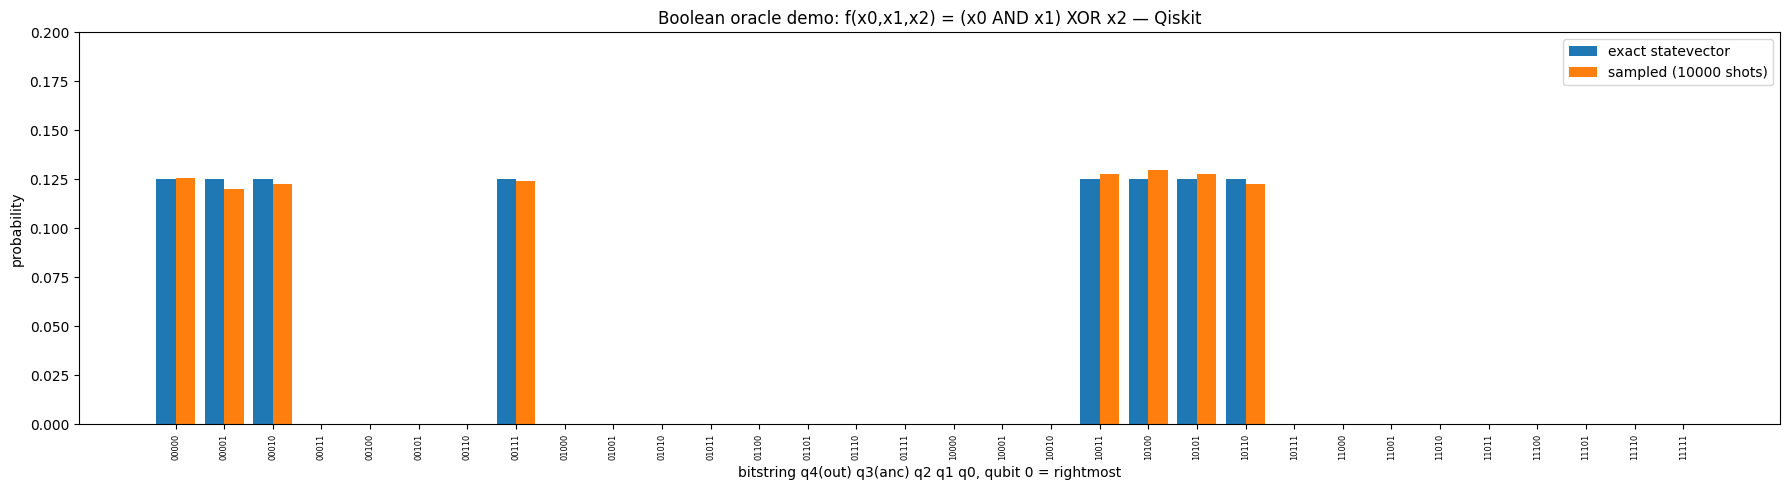

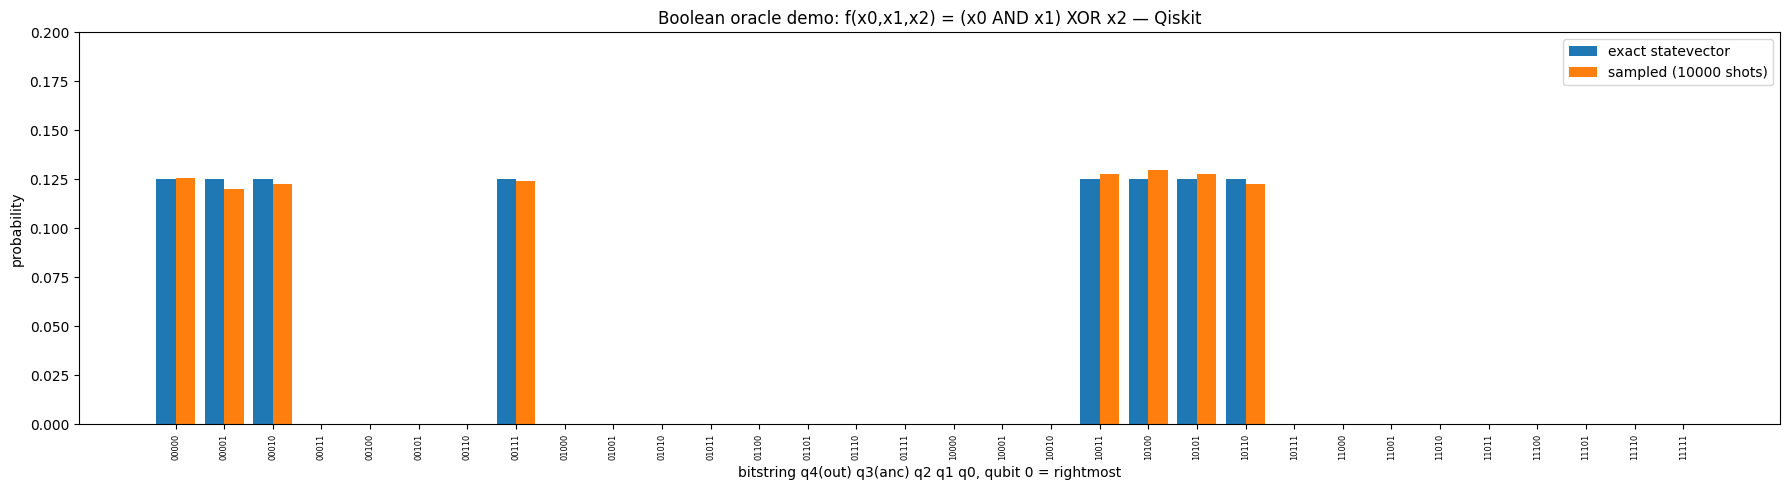

In [8]:
# Histogram: matplotlib bar chart, saved to file
bitstrings_sorted = sorted(QISKIT_PROBS_EXACT.keys())
exact_vals = [QISKIT_PROBS_EXACT[b] for b in bitstrings_sorted]
sampled_vals = [QISKIT_PROBS_SAMPLED[b] for b in bitstrings_sorted]

fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(len(bitstrings_sorted))
width = 0.4
ax.bar(x - width/2, exact_vals, width, label="exact statevector", color="#1f77b4")
ax.bar(x + width/2, sampled_vals, width, label=f"sampled ({SHOTS} shots)", color="#ff7f0e")
ax.set_xticks(x)
ax.set_xticklabels(bitstrings_sorted, rotation=90, fontsize=6)
ax.set_xlabel("bitstring q4(out) q3(anc) q2 q1 q0, qubit 0 = rightmost")
ax.set_ylabel("probability")
ax.set_title("Boolean oracle demo: f(x0,x1,x2) = (x0 AND x1) XOR x2 — Qiskit")
ax.set_ylim(0, 0.2)
ax.legend()
fig.tight_layout()
fig.savefig(f"{TOPIC_SLUG}_qiskit_histogram.png", dpi=150, bbox_inches="tight")
fig


In [9]:
# Resource counts
print("Circuit depth:", qc.depth())
print("Gate counts:", dict(qc.count_ops()))


Circuit depth: 4
Gate counts: {'h': 3, 'barrier': 2, 'ccx': 2, 'cx': 2}


### Convention notes (plain text summary)

- **Bit-order convention:** qubit 0 = rightmost character; Qiskit uses this natively, no
  reversal applied.
- **Global phase convention:** identical rule as all companion notebooks.
- **Basis ordering for matrices:** ascending binary order `|00000> ... |11111>` (5 qubits).
- **Why only 8 of 32 outcomes are possible:** the oracle is a permutation (built from
  Toffoli + CNOTs), deterministically pairing every input `x` with `ANCILLA=0` and
  `OUTPUT=f(x)`.


In [10]:
# Final result
QISKIT_RESULT = {b: QISKIT_PROBS_EXACT[b] for b in sorted(QISKIT_PROBS_EXACT)}
print("QISKIT_RESULT (nonzero entries) =")
for b, p in QISKIT_RESULT.items():
    if p > 1e-9:
        print(f"  '{b}': {p:.6f}")


QISKIT_RESULT (nonzero entries) =
  '00000': 0.125000
  '00001': 0.125000
  '00010': 0.125000
  '00111': 0.125000
  '10011': 0.125000
  '10100': 0.125000
  '10101': 0.125000
  '10110': 0.125000


In [11]:
# Diff-check block (run AFTER also running the CUDA-Q notebook and pasting its CUDAQ_RESULT below)
HAND_COMPUTED_EXPECTED = {format(i, f'0{TOTAL_QUBITS}b'): 0.0 for i in range(2**TOTAL_QUBITS)}
for x in range(2**N_QUBITS):
    x0, x1, x2 = (x >> 0) & 1, (x >> 1) & 1, (x >> 2) & 1
    fx = f_boolean(x0, x1, x2)
    idx = x | (fx << OUTPUT_QUBIT)  # ancilla bit = 0
    HAND_COMPUTED_EXPECTED[format(idx, f'0{TOTAL_QUBITS}b')] = 1/(2**N_QUBITS)

max_delta_vs_hand = max(abs(QISKIT_RESULT[b] - HAND_COMPUTED_EXPECTED[b]) for b in QISKIT_RESULT)
print("Max delta between QISKIT_RESULT and hand-computed expected:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-3

# CUDAQ_RESULT = { ... }  # <- paste the dict printed at the end of the CUDA-Q notebook here
# max_delta = max(abs(QISKIT_RESULT[b] - CUDAQ_RESULT[b]) for b in QISKIT_RESULT)
# print("Max probability delta between QISKIT_RESULT and CUDAQ_RESULT:", max_delta)
# assert max_delta < 1e-3, "Qiskit and CUDA-Q boolean-oracle results disagree beyond tolerance!"


Max delta between QISKIT_RESULT and hand-computed expected: 5.551115123125783e-17
